In [ ]:
## Comparison the Three TC Mozambique 

In [47]:
from climada_petals.hazard import TCForecast
import logging
import datetime
import os
import numpy as np
import geopandas as gpd
import pickle

In [48]:
### impacts calculated
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_IDAI = pickle.load(file)
with open('/cluster/work/climate/gespejo/IDAI_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_IDAI = pickle.load(file)

In [49]:
### impacts calculated
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_FREDDY = pickle.load(file)
with open('/cluster/work/climate/gespejo/FREDDY_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_FREDDY = pickle.load(file)

In [50]:
### impacts calculated
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/imph2_impp1.pkl', 'rb') as file:
    imph2_impp1_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/ed2_impp1.pkl', 'rb') as file:
    ed2_impp1_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/impp1_disrupted.pkl', 'rb') as file:
    impp1_disrupted_KENNETH = pickle.load(file)
with open('/cluster/work/climate/gespejo/KENNETH_picklefiles/rd2_disrupted_impp1.pkl', 'rb') as file:
    rd2_disrupted_impp1_KENNETH = pickle.load(file)

In [51]:
from climada.entity.exposures.base import Exposures
gdf_worldpop_MOZ = Exposures.from_raster ('/cluster/work/climate/gespejo/data/infrastructure/population/moz_ppp_2020_1km_Aggregated_UNadj.tif')

In [52]:
gdf_worldpop_MOZ.set_geometry_points()

In [53]:
###SUBNATIONAL DIVISION 
import geopandas as gpd
geofile_MOZ = '/cluster/work/climate/gespejo/data/infrastructure/Mozambique_results_MOZ/gadm41_MOZ_shp/gadm41_MOZ_1.shp'
gadm_MOZ = gpd.read_file(geofile_MOZ)

In [54]:
gdf_worldpop_MOZ.gdf

,longitude,latitude,value,geometry
0,30.219583,-10.471250,0.0,POINT (30.21958 -10.47125)
1,30.227917,-10.471250,0.0,POINT (30.22792 -10.47125)
2,30.236250,-10.471250,0.0,POINT (30.23625 -10.47125)
3,30.244583,-10.471250,0.0,POINT (30.24458 -10.47125)
4,30.252917,-10.471250,0.0,POINT (30.25292 -10.47125)
...,...,...,...,...
2509195,40.802917,-26.862916,0.0,POINT (40.80292 -26.86292)
2509196,40.811250,-26.862916,0.0,POINT (40.81125 -26.86292)
2509197,40.819583,-26.862916,0.0,POINT (40.81958 -26.86292)
2509198,40.827917,-26.862916,0.0,POINT (40.82792 -26.86292)


In [55]:
import geopandas as gpd

# Make sure both GeoDataFrames are in the same CRS
gdf_worldpop_MOZ = gdf_worldpop_MOZ.gdf.to_crs(gadm_MOZ.crs)

# Spatial join: assign each population point a province name from GADM
gdf_worldpop_MOZ = gpd.sjoin(
    gdf_worldpop_MOZ,
    gadm_MOZ[['NAME_1', 'geometry']],  # keep only needed columns
    how='left',
    predicate='within'  # or 'within' for point-in-polygon
)

In [56]:
gdf_worldpop_MOZ 

,longitude,latitude,value,geometry,index_right,NAME_1
0,30.219583,-10.471250,0.0,POINT (30.21958 -10.47125),NaN,NaN
1,30.227917,-10.471250,0.0,POINT (30.22792 -10.47125),NaN,NaN
2,30.236250,-10.471250,0.0,POINT (30.23625 -10.47125),NaN,NaN
3,30.244583,-10.471250,0.0,POINT (30.24458 -10.47125),NaN,NaN
4,30.252917,-10.471250,0.0,POINT (30.25292 -10.47125),NaN,NaN
...,...,...,...,...,...,...
2509195,40.802917,-26.862916,0.0,POINT (40.80292 -26.86292),NaN,NaN
2509196,40.811250,-26.862916,0.0,POINT (40.81125 -26.86292),NaN,NaN
2509197,40.819583,-26.862916,0.0,POINT (40.81958 -26.86292),NaN,NaN
2509198,40.827917,-26.862916,0.0,POINT (40.82792 -26.86292),NaN,NaN


In [57]:
pop_per_province = gdf_worldpop_MOZ.dropna(subset=['NAME_1']).groupby('NAME_1')['value'].sum()

In [58]:
## Comparing relatives values of affectation 

In [59]:
rename_dict = {
    'imph2_MOZ_new_FREDDY_20230306120000': '5 days',
    'imph2_MOZ_new_FREDDY_20230307120000': '4 days',
    'imph2_MOZ_new_FREDDY_20230308120000': '3 days',
    'imph2_MOZ_new_FREDDY_20230309120000': '2 days',
    'imph2_MOZ_new_FREDDY_20230310120000': '1 day',
    'imph2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
imph2_impp1_FREDDY = {rename_dict.get(k, k): v for k, v in imph2_impp1_FREDDY.items() if k in rename_dict}

In [60]:
rename_dict_ed2 = {
    'ed2_MOZ_new_FREDDY_20230306120000': '5 days',
    'ed2_MOZ_new_FREDDY_20230307120000': '4 days',
    'ed2_MOZ_new_FREDDY_20230308120000': '3 days',
    'ed2_MOZ_new_FREDDY_20230309120000': '2 days',
    'ed2_MOZ_new_FREDDY_20230310120000': '1 day',
    'ed2_MOZ_new_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
ed2_impp1_FREDDY = {rename_dict_ed2.get(k, k): v for k, v in ed2_impp1_FREDDY .items() if k in rename_dict_ed2}

In [61]:
rename_dict_impp1 = {
    'impp1_MOZ_FREDDY_20230306120000': '5 days',
    'impp1_MOZ_FREDDY_20230307120000': '4 days',
    'impp1_MOZ_FREDDY_20230308120000': '3 days',
    'impp1_MOZ_FREDDY_20230309120000': '2 days',
    'impp1_MOZ_FREDDY_20230310120000': '1 day',
    'impp1_MOZ_FREDDY_20230311120000': 'landfall'
}
# Rename keys using rename_dict
impp1_disrupted_FREDDY = {rename_dict_impp1.get(k, k): v for k, v in impp1_disrupted_FREDDY.items() if k in rename_dict_impp1}

In [63]:
rename_dict_rd2 = {
    '20230306120000': '5 days',
    '20230307120000': '4 days',
    '20230308120000': '3 days',
    '20230309120000': '2 days',
    '20230310120000': '1 day',
    '20230311120000': 'landfall'
}
# Rename keys using rename_dict
rd2_disrupted_impp1_FREDDY = {rename_dict_rd2.get(k, k): v for k, v in rd2_disrupted_impp1_FREDDY.items() if k in rename_dict_rd2}

In [64]:
rd2_disrupted_impp1_FREDDY

{'5 days':            osm_id         0    1    2         3         4         5    6    7  \
 0      1000099478  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 1      1000099479  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 2      1000430904  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 3      1001375959  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 4      1001694070  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 ...           ...       ...  ...  ...       ...       ...       ...  ...  ...   
 80393   999858614  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80394   999859262  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80395   999860028  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80396   999865566  0.024018  0.0  0.0  0.219914  0.388050  0.344996  0.0  0.0   
 80397   999866041  0.024981  0.0  0.0  0.123302  0.385317  0.338101  0.0  0.0   
 
    

In [65]:
### FREDDY TROPICAL CYCLONE 
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times and province colors
lead_times = ['5 days', '4 days', '3 days', '2 days', '1 day']

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for lt in lead_times:
    df_h2_FREDDY = imph2_impp1_FREDDY[lt]
    leadtime_province_h2[lt] = df_h2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

    df_ed2_FREDDY = ed2_impp1_FREDDY[lt]
    leadtime_province_ed2[lt] = df_ed2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

    df_p1_FREDDY = impp1_disrupted_FREDDY[lt]
    leadtime_province_p1[lt] = df_p1_FREDDY.groupby('NAME_1')['people'].sum()

    df_rd2_FREDDY = rd2_disrupted_impp1_FREDDY[lt]
    leadtime_province_rd2[lt] = df_rd2_FREDDY.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_FREDDY = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_FREDDY = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_FREDDY = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_FREDDY = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_FREDDY["Total"] = df_h2_FREDDY.sum(axis=1)
df_ed2_FREDDY["Total"] = df_ed2_FREDDY.sum(axis=1)
df_p1_FREDDY["Total"] = df_p1_FREDDY.sum(axis=1)
df_rd2_FREDDY["Total"] = df_rd2_FREDDY.sum(axis=1)

In [66]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times
lead_times = ['4 days', '3 days', '2 days', '1 day']

# Get sorted keys per dictionary
keys_h2 = list(imph2_impp1_IDAI.keys())
keys_ed2 = list(ed2_impp1_IDAI.keys())
keys_p1 = list(impp1_disrupted_IDAI.keys())
keys_rd2 = list(rd2_disrupted_impp1_IDAI.keys())

# Ensure 4 keys each
#assert len(keys_h2) == 4 and len(keys_ed2) == 4 and len(keys_p1) == 4 and len(keys_rd2) == 4

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for i, lt in enumerate(lead_times):
    df_h2 = imph2_impp1_IDAI[keys_h2[i]]
    leadtime_province_h2[lt] = df_h2.groupby('NAME_1')['pp_affected'].sum()

    df_ed2 = ed2_impp1_IDAI[keys_ed2[i]]
    leadtime_province_ed2[lt] = df_ed2.groupby('NAME_1')['pp_affected'].sum()

    df_p1 = impp1_disrupted_IDAI[keys_p1[i]]
    leadtime_province_p1[lt] = df_p1.groupby('NAME_1')['people'].sum()

    df_rd2 = rd2_disrupted_impp1_IDAI[keys_rd2[i]]
    leadtime_province_rd2[lt] = df_rd2.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_IDAI = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_IDAI = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_IDAI = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_IDAI = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_IDAI["Total"] = df_h2_IDAI.sum(axis=1)
df_ed2_IDAI["Total"] = df_ed2_IDAI.sum(axis=1)
df_p1_IDAI["Total"] = df_p1_IDAI.sum(axis=1)
df_rd2_IDAI["Total"] = df_rd2_IDAI.sum(axis=1)

In [67]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define lead times in order (corresponds to first and second key)
lead_times = ['2 days', '1 day']

# Sort keys to ensure proper ordering
keys_h2 = sorted(imph2_impp1_KENNETH.keys())
keys_ed2 = sorted(ed2_impp1_KENNETH.keys())
keys_p1  = sorted(impp1_disrupted_KENNETH.keys())
keys_rd2 = sorted(rd2_disrupted_impp1_KENNETH.keys())

# Keep only first two keys (2 days and 1 day before landfall)
keys_h2 = keys_h2[:2]
keys_ed2 = keys_ed2[:2]
keys_p1  = keys_p1[:2]
keys_rd2 = keys_rd2[:2]

# Initialize data structures
leadtime_province_h2 = {}
leadtime_province_ed2 = {}
leadtime_province_p1 = {}
leadtime_province_rd2 = {}

# Aggregate data per lead time and province
for i, lt in enumerate(lead_times):
    df_h2 = imph2_impp1_KENNETH[keys_h2[i]]
    leadtime_province_h2[lt] = df_h2.groupby('NAME_1')['pp_affected'].sum()

    df_ed2 = ed2_impp1_KENNETH[keys_ed2[i]]
    leadtime_province_ed2[lt] = df_ed2.groupby('NAME_1')['pp_affected'].sum()

    df_p1 = impp1_disrupted_KENNETH[keys_p1[i]]
    leadtime_province_p1[lt] = df_p1.groupby('NAME_1')['people'].sum()

    df_rd2 = rd2_disrupted_impp1_KENNETH[keys_rd2[i]]
    leadtime_province_rd2[lt] = df_rd2.groupby('NAME_1')['pp_affected'].sum()

# Convert to DataFrames and fill missing data
df_h2_KENNETH = pd.DataFrame(leadtime_province_h2).T.fillna(0)
df_ed2_KENNETH = pd.DataFrame(leadtime_province_ed2).T.fillna(0)
df_p1_KENNETH = pd.DataFrame(leadtime_province_p1).T.fillna(0)
df_rd2_KENNETH = pd.DataFrame(leadtime_province_rd2).T.fillna(0)

# Add total column per day for each impact type
df_h2_KENNETH["Total"] = df_h2_KENNETH.sum(axis=1)
df_ed2_KENNETH["Total"] = df_ed2_KENNETH.sum(axis=1)
df_p1_KENNETH["Total"] = df_p1_KENNETH.sum(axis=1)
df_rd2_KENNETH["Total"] = df_rd2_KENNETH.sum(axis=1)

In [68]:
df_h2_IDAI

NAME_1,Inhambane,Manica,Sofala,Zambezia,Total
4 days,0.0,0.0,34414.0,1280.0,35694.0
3 days,0.0,0.0,34063.0,93.0,34156.0
2 days,0.0,264.0,34312.0,1306.0,35882.0
1 day,0.0,121.0,38659.0,0.0,38780.0


In [69]:
df_h2_FREDDY

NAME_1,Nampula,Sofala,Zambezia,Total
5 days,1719.0,0.0,33519.0,35238.0
4 days,0.0,0.0,23809.0,23809.0
3 days,0.0,0.0,2535.0,2535.0
2 days,0.0,0.0,26854.0,26854.0
1 day,0.0,2122.0,23657.0,25779.0


In [70]:
df_h2_KENNETH 

NAME_1,Cabo Delgado,Total
2 days,0,0
1 day,688,688


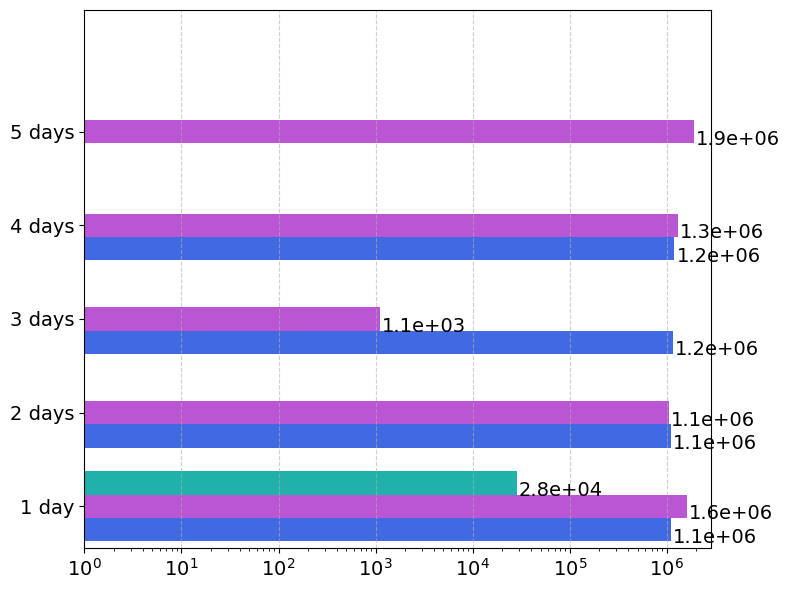

In [71]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator, LogFormatterSciNotation

# Define cyclone colors
colors = {
    "Idai": "royalblue",         # stable blue
    "Freddy": "mediumorchid",    # visible purple
    "Kenneth": "#20B2AA"         # teal
}

# Prepare data
wind_comparison = {
    "Idai": df_p1_IDAI["Total"],
    "Freddy": df_p1_FREDDY["Total"],
    "Kenneth": df_p1_KENNETH["Total"]
}
df_wind = pd.DataFrame(wind_comparison).fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.25
y = np.arange(len(df_wind.index))

for i, (cyclone, color) in enumerate(colors.items()):
    values = df_wind[cyclone]
    ax.barh(y + i * bar_width, values, height=bar_width, label=cyclone, color=color)

    for j, val in enumerate(values):
        if val > 0:
            ax.text(val * 1.05, y[j] + i * bar_width - 0.08, f"{val:.1e}", va='center', fontsize=14)

# Axis formatting
ax.set_xscale('log')
ax.set_xlim(left=1, right=df_wind.values.max() * 1.5)
ax.xaxis.set_major_locator(LogLocator(base=10.0))
ax.xaxis.set_major_formatter(LogFormatterSciNotation())

ax.set_yticks(y + bar_width)
ax.set_yticklabels(df_wind.index, fontsize=14)
ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))

#ax.set_xlabel("People Affected (log scale)", fontsize=18, labelpad=20)
#ax.set_title("Direct Affected by Wind", fontsize=20, pad=20)
ax.tick_params(axis='x', labelsize=14)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Legend
#ax.legend(title="Tropical Cyclone", fontsize=14, title_fontsize=14, loc='best')

# Save and show
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/TC_Comparison/disrupted_pp1_wind.png", dpi=800, bbox_inches='tight')
plt.show()

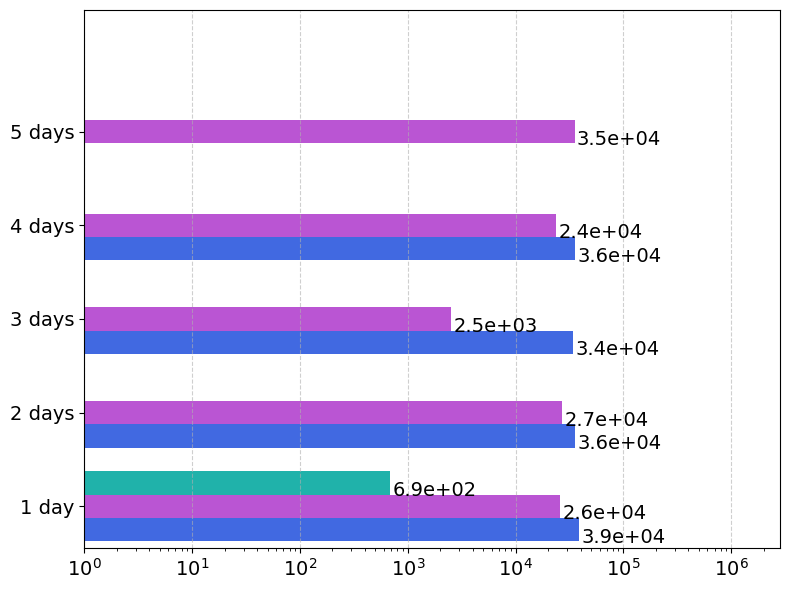

In [72]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator, LogFormatterSciNotation

# Define cyclone colors
colors = {
    "Idai": "royalblue",         # stable blue
    "Freddy": "mediumorchid",    # visible purple
    "Kenneth": "#20B2AA"         # teal
}

# Prepare data
hospital_comparison = {
    "Idai": df_h2_IDAI["Total"],
    "Freddy": df_h2_FREDDY["Total"],
    "Kenneth": df_h2_KENNETH["Total"]
}
df_hospitals = pd.DataFrame(hospital_comparison).fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.25
y = np.arange(len(df_wind.index))

for i, (cyclone, color) in enumerate(colors.items()):
    values = df_hospitals[cyclone]
    ax.barh(y + i * bar_width, values, height=bar_width, label=cyclone, color=color)

    for j, val in enumerate(values):
        if val > 0:
            ax.text(val * 1.05, y[j] + i * bar_width - 0.08, f"{val:.1e}", va='center', fontsize=14)

# Axis formatting
ax.set_xscale('log')
ax.set_xlim(left=1, right=df_wind.values.max() * 1.5)
ax.xaxis.set_major_locator(LogLocator(base=10.0))
ax.xaxis.set_major_formatter(LogFormatterSciNotation())

ax.set_yticks(y + bar_width)
ax.set_yticklabels(df_wind.index, fontsize=14)
ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))

#ax.set_xlabel("People Affected (log scale)", fontsize=18, labelpad=20)
#ax.set_title("Direct Affected by Wind", fontsize=20, pad=20)
ax.tick_params(axis='x', labelsize=14)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Legend
#ax.legend(title="Tropical Cyclone", fontsize=14, title_fontsize=14, loc='best')

# Save and show
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/TC_Comparison/disrupted_h2_people.png", dpi=800, bbox_inches='tight')
plt.show()

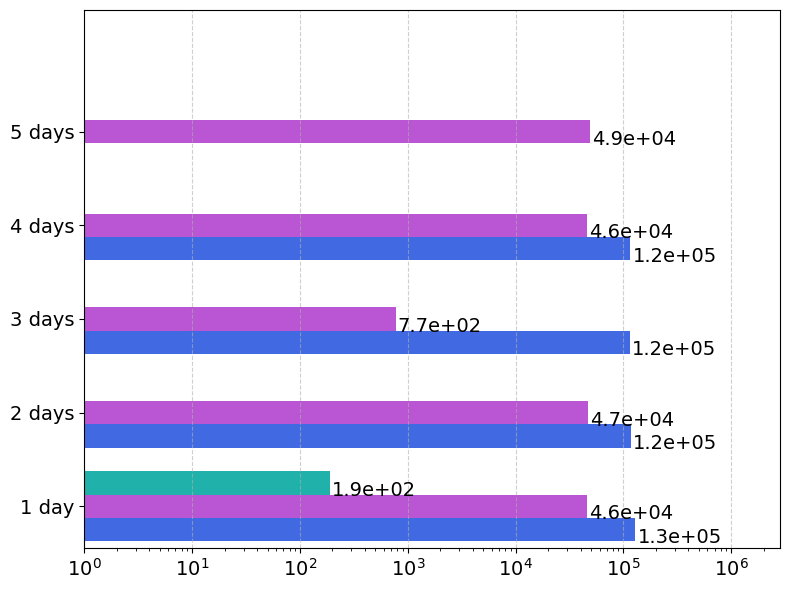

In [73]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator, LogFormatterSciNotation

# Define cyclone colors
colors = {
    "Idai": "royalblue",         # stable blue
    "Freddy": "mediumorchid",    # visible purple
    "Kenneth": "#20B2AA"         # teal
}

# Prepare data
school_comparison = {
    "Idai": df_ed2_IDAI["Total"],
    "Freddy": df_ed2_FREDDY["Total"],
    "Kenneth": df_ed2_KENNETH["Total"]
}

df_school = pd.DataFrame(school_comparison).fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.25
y = np.arange(len(df_wind.index))

for i, (cyclone, color) in enumerate(colors.items()):
    values = df_school[cyclone]
    ax.barh(y + i * bar_width, values, height=bar_width, label=cyclone, color=color)

    for j, val in enumerate(values):
        if val > 0:
            ax.text(val * 1.05, y[j] + i * bar_width - 0.08, f"{val:.1e}", va='center', fontsize=14)

# Axis formatting
ax.set_xscale('log')
ax.set_xlim(left=1, right=df_wind.values.max() * 1.5)
ax.xaxis.set_major_locator(LogLocator(base=10.0))
ax.xaxis.set_major_formatter(LogFormatterSciNotation())

ax.set_yticks(y + bar_width)
ax.set_yticklabels(df_wind.index, fontsize=14)
ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))

#ax.set_xlabel("People Affected (log scale)", fontsize=18, labelpad=20)
#ax.set_title("Direct Affected by Wind", fontsize=20, pad=20)
ax.tick_params(axis='x', labelsize=14)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Legend
#ax.legend(title="Tropical Cyclone", fontsize=14, title_fontsize=14, loc='best')

# Save and show
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/TC_Comparison/disrupted_ed2_people.png", dpi=800, bbox_inches='tight')
plt.show()

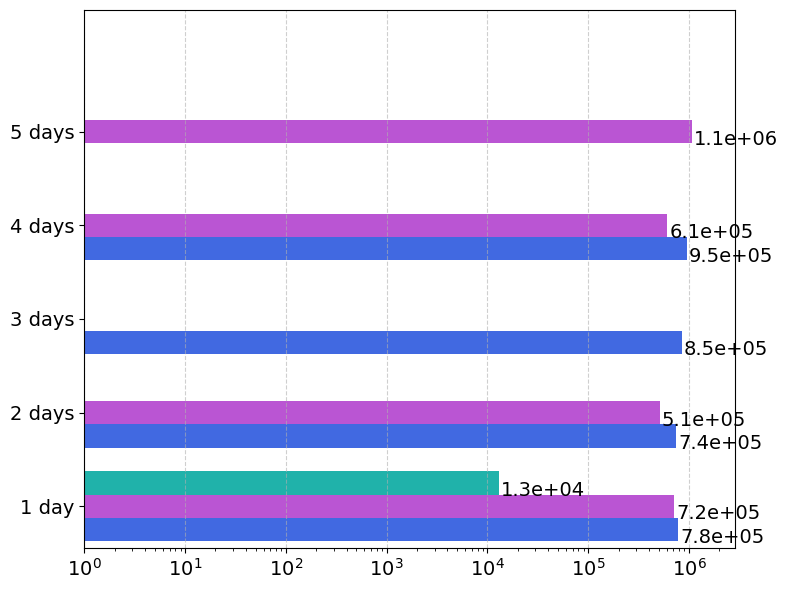

In [74]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator, LogFormatterSciNotation

# Define cyclone colors
colors = {
    "Idai": "royalblue",         # stable blue
    "Freddy": "mediumorchid",    # visible purple
    "Kenneth": "#20B2AA"         # teal
}

# Prepare data
road_comparison = {
    "Idai": df_rd2_IDAI["Total"],
    "Freddy": df_rd2_FREDDY["Total"],
    "Kenneth": df_rd2_KENNETH["Total"]
}

df_road = pd.DataFrame(road_comparison).fillna(0)

# Plotting
fig, ax = plt.subplots(figsize=(8, 6))
bar_width = 0.25
y = np.arange(len(df_wind.index))

for i, (cyclone, color) in enumerate(colors.items()):
    values = df_road[cyclone]
    ax.barh(y + i * bar_width, values, height=bar_width, label=cyclone, color=color)

    for j, val in enumerate(values):
        if val > 0:
            ax.text(val * 1.05, y[j] + i * bar_width - 0.08, f"{val:.1e}", va='center', fontsize=14)

# Axis formatting
ax.set_xscale('log')
ax.set_xlim(left=1, right=df_wind.values.max() * 1.5)
ax.xaxis.set_major_locator(LogLocator(base=10.0))
ax.xaxis.set_major_formatter(LogFormatterSciNotation())

ax.set_yticks(y + bar_width)
ax.set_yticklabels(df_wind.index, fontsize=14)
ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))

#ax.set_xlabel("People Affected (log scale)", fontsize=18, labelpad=20)
#ax.set_title("Direct Affected by Wind", fontsize=20, pad=20)
ax.tick_params(axis='x', labelsize=14)
ax.grid(axis='x', linestyle='--', alpha=0.6)

# Legend
#ax.legend(title="Tropical Cyclone", fontsize=14, title_fontsize=14, loc='best')

# Save and show
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/TC_Comparison/disrupted_rd2_people.png", dpi=800, bbox_inches='tight')
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Define cyclone colors
colors = {
    "Idai": "royalblue",
    "Freddy": "mediumorchid",
    "Kenneth": "#20B2AA"
}

# Create dummy handles for the legend
handles = [mpatches.Patch(color=color, label=name) for name, color in colors.items()]

# Create a separate figure just for the legend
fig, ax = plt.subplots(figsize=(4, 1))
ax.legend(
    handles,
    [h.get_label() for h in handles],
    title="Tropical Cyclone",
    fontsize=14,
    title_fontsize=14,
    loc='center',
    ncol=3,
    frameon=False
)
ax.axis('off')

# Save legend as a standalone image
plt.tight_layout()
fig.savefig("/cluster/home/gespejo/TC_Comparison/tc_legend_only.png", dpi=800, bbox_inches='tight')
plt.show()

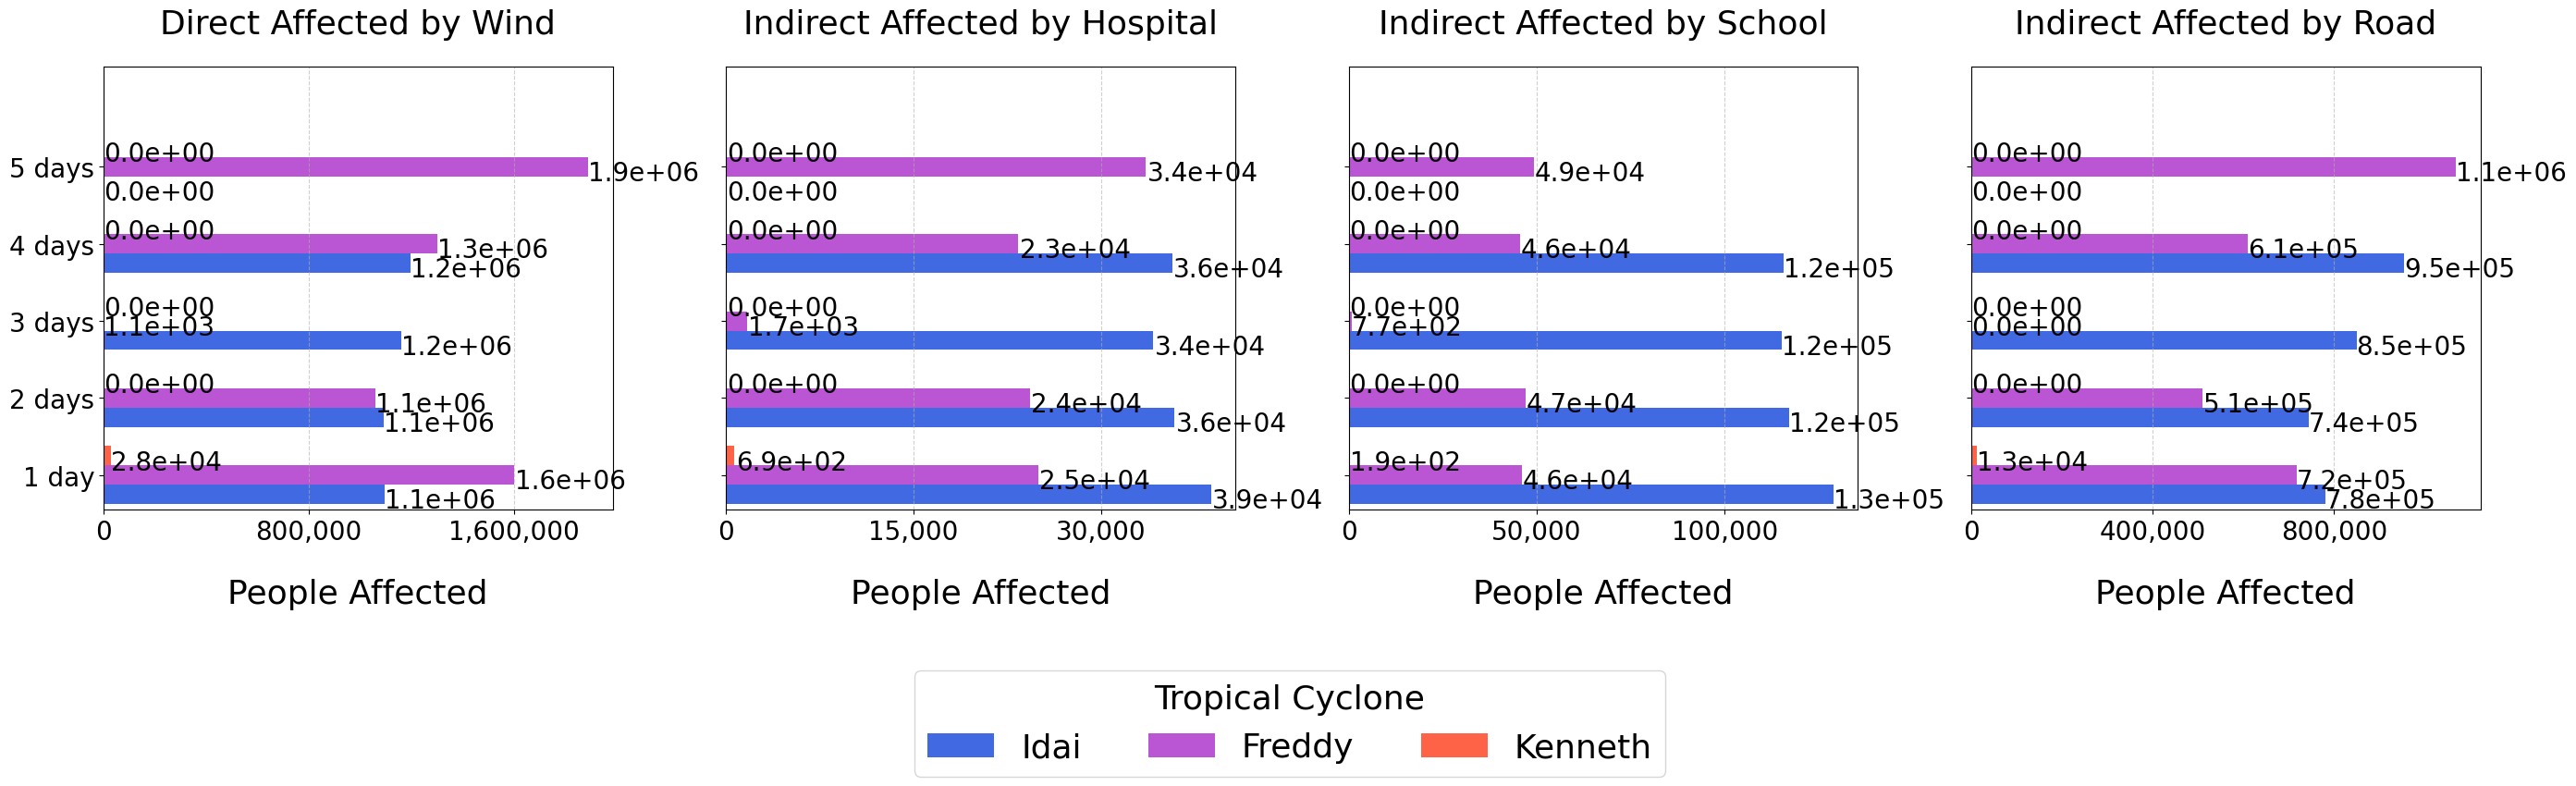

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter, MaxNLocator

# Define cyclone colors
colors = {
    "Idai": "royalblue",
    "Freddy": "mediumorchid",
    "Kenneth": "tomato"
}

# Helper function to generate the comparison plot
def plot_four_comparisons(dfs, titles):
    fig, axs = plt.subplots(ncols=4, figsize=(28, 8), sharey=True)
    bar_width = 0.25

    for idx, (df_dict, title) in enumerate(zip(dfs, titles)):
        ax = axs[idx]
        df_comparison = pd.DataFrame(df_dict).fillna(0)
        y = np.arange(len(df_comparison.index))

        for i, (cyclone, color) in enumerate(colors.items()):
            ax.barh(y + i * bar_width, df_comparison[cyclone], height=bar_width, label=cyclone, color=color)

            for j, val in enumerate(df_comparison[cyclone]):
                # Format bar-end labels in scientific notation
                label = f"{val:.1e}"
                ax.text(val + 100, y[j] + i * bar_width - 0.08, label, va='center', fontsize=20)

        ax.set_yticks(y + bar_width)
        ax.set_yticklabels(df_comparison.index, fontsize=20)
        ax.set_ylim(-0.2, len(y) - 0.2 + bar_width * len(colors))
        ax.set_xlabel("People Affected", fontsize=26, labelpad=26)
        ax.set_title(title, fontsize=26, pad=26)
        ax.tick_params(axis='x', labelsize=20)
        ax.grid(axis='x', linestyle='--', alpha=0.6)

        # X-axis with commas and only 3 ticks
        ax.xaxis.set_major_locator(MaxNLocator(nbins=3))
        ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

    # Shared legend
    handles, labels = axs[0].get_legend_handles_labels()
    fig.legend(
        handles, labels,
        title="Tropical Cyclone",
        fontsize=26,
        title_fontsize=26,
        loc='lower center',
        ncol=3,
        bbox_to_anchor=(0.5, -0.08)
    )
    plt.tight_layout(rect=[0, 0.15, 1, 1])
    fig.savefig("/cluster/home/gespejo/MOZ_struc_plots_Freddy/TCs_comparison.png", dpi=300, bbox_inches='tight')
    plt.show()

# Define the comparison dictionaries and titles
hospital_comparison = {
    "Idai": df_h2_IDAI["Total"],
    "Freddy": df_h2_FREDDY["Total"],
    "Kenneth": df_h2_KENNETH["Total"]
}

school_comparison = {
    "Idai": df_ed2_IDAI["Total"],
    "Freddy": df_ed2_FREDDY["Total"],
    "Kenneth": df_ed2_KENNETH["Total"]
}

road_comparison = {
    "Idai": df_rd2_IDAI["Total"],
    "Freddy": df_rd2_FREDDY["Total"],
    "Kenneth": df_rd2_KENNETH["Total"]
}

wind_comparison = {
    "Idai": df_p1_IDAI["Total"],
    "Freddy": df_p1_FREDDY["Total"],
    "Kenneth": df_p1_KENNETH["Total"]
}

# Call the function with all four comparisons
plot_four_comparisons(
    [wind_comparison, hospital_comparison, school_comparison, road_comparison],
    ["Direct Affected by Wind", "Indirect Affected by Hospital", "Indirect Affected by School", "Indirect Affected by Road"])